# Daily Bloomberg Data: Time-Series Properties, Long-Sample Tests and Basis

**MScFE 690 Capstone, Commodities track, Topic 3.** Minh Tien Phung · Minh Chau Pham. Companion to `weather_agri_commodities.ipynb`; the report discusses the results.

Daily CBOT corn, wheat and soybean futures and USDA cash prices, 1990 to October 2026, supplied by our instructor: cleaning, time-series properties (serial correlation, mean reversion, ARIMA, GARCH, seasonality), weather and prices, corn and wheat over 36 years, a US vs EU comparison with cash prices, and the basis.

**Data access.** Bloomberg data may not be redistributed, so `data/raw/Ags.xlsx` is not in the public repository (see `.gitignore`); the saved outputs show the results.

## 1. Setup

In [1]:
import calendar
import platform
import warnings
from pathlib import Path

import arch
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import statsmodels.api as sm
from arch import arch_model
from IPython.display import display
from pandas.tseries.holiday import USFederalHolidayCalendar
from scipy import stats
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import acf, adfuller, coint, kpss
from statsmodels.tsa.vector_ar.vecm import coint_johansen, select_order

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", "{:,.3f}".format)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

DATA_DIR = Path("data/raw")
BBG_FILE = DATA_DIR / "Ags.xlsx"   # Bloomberg extract from the instructor (not in the public repository)
LAST_YEAR = 2025                   # last complete year for annual statistics, weather and yields
EU_LAST_WEEK = "2026-07-31"        # EU cereal prices change definition in August 2026 (main notebook, Section 3)
assert BBG_FILE.exists(), "This notebook needs data/raw/Ags.xlsx (Bloomberg data supplied by the instructor)."
print(f"Python {platform.python_version()} | numpy {np.__version__} | pandas {pd.__version__} | scipy {scipy.__version__} | "
      f"statsmodels {sm.__version__} | arch {arch.__version__} | matplotlib {matplotlib.__version__}")

Python 3.10.14 | numpy 1.26.4 | pandas 2.3.0 | scipy 1.15.3 | statsmodels 0.14.4 | arch 7.0.0 | matplotlib 3.8.3


In [2]:
COLORS = {"corn": "#2a78d6", "wheat": "#eb6834", "hrw": "#9c4a1a", "soy": "#1baf7a"}
REGION = {"US": "#4a3aa7", "EU": "#e34948"}
INK, INK2, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"

plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlesize": 10.5, "axes.titleweight": "bold",
    "axes.titlecolor": INK, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "grid.linestyle": "-",
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "lines.linewidth": 1.5, "legend.frameon": False, "legend.fontsize": 8.5, "font.size": 9,
})

SERIES = {   # Bloomberg ticker: (column, description, unit)
    "C 1 Comdty": ("corn_fut", "CBOT corn, front month (par grade No. 2 yellow)", "US cents/bu"),
    "W 1 Comdty": ("wheat_fut", "CBOT soft red winter (SRW) wheat, front month", "US cents/bu"),
    "KW1 Comdty": ("hrw_fut", "KC hard red winter (HRW) wheat, front month", "US cents/bu"),
    "S 1 Comdty": ("soy_fut", "CBOT soybeans, front month (par grade No. 2 yellow)", "US cents/bu"),
    "CORNILNC Index": ("corn_cash", "USDA cash corn, North Central Illinois, No. 2 yellow", "USD/bu"),
    "SOYBTC1Y Index": ("soy_cash", "USDA cash soybeans, Central Illinois processors, No. 1 yellow", "USD/bu"),
    "WEAT2RDR Index": ("wheat_cash", "USDA cash SRW wheat, Toledo (on the river), No. 2", "USD/bu"),
}
LABELS = {"corn_fut": "Corn futures", "wheat_fut": "SRW wheat futures", "hrw_fut": "HRW wheat futures",
          "soy_fut": "Soybean futures", "corn_cash": "Corn cash (Illinois)", "soy_cash": "Soybean cash (Illinois)",
          "wheat_cash": "SRW wheat cash (Toledo)", "corn_eu": "EU maize", "wheat_eu": "EU wheat"}
COLOR_OF = {"corn_fut": COLORS["corn"], "wheat_fut": COLORS["wheat"], "hrw_fut": COLORS["hrw"], "soy_fut": COLORS["soy"],
            "corn_cash": COLORS["corn"], "soy_cash": COLORS["soy"], "wheat_cash": COLORS["wheat"]}
FUT = ["corn_fut", "wheat_fut", "hrw_fut", "soy_fut"]
CASH = {"corn_cash": "corn_fut", "soy_cash": "soy_fut", "wheat_cash": "wheat_fut"}   # cash series: matching futures
CONTRACT_MONTHS = {"corn_fut": [3, 5, 7, 9, 12], "wheat_fut": [3, 5, 7, 9, 12], "hrw_fut": [3, 5, 7, 9, 12],
                   "soy_fut": [1, 3, 5, 7, 8, 9, 11]}
WEEKS_PER_MONTH = 52 / 12


def fig_title(fig, text):
    fig.suptitle(text, x=0.01, ha="left", fontsize=11, fontweight="bold", color=INK)


def fmt_p(p):
    return f"{p:.3f}" if p >= 0.001 else "<0.001"


def nw_lags(n):
    """Number of lags for HAC (Newey-West) standard errors: the rule of thumb floor(4 (n/100)^(2/9))."""
    return int(4 * (n / 100) ** (2 / 9))


def hl_from_lambda(lam):
    """Half-life (periods) for an adjustment speed lambda in (-1, 0); infinite otherwise."""
    return np.log(0.5) / np.log(1 + lam) if -1 < lam < 0 else np.inf

## 2. Data
`Sheet2` of the workbook holds the values (`Sheet1` holds the Bloomberg formulas). Each series is the daily last price (`PX_LAST`). The instructor's notes in the workbook define the series and the basis.

In [3]:
raw = pd.read_excel(BBG_FILE, sheet_name="Sheet2", header=None)
tickers = raw.iloc[3, 1:].tolist()                        # row 4: tickers; rows 5-6: field names; data from row 7
bbg = raw.iloc[6:, 1:].set_axis([SERIES[t][0] for t in tickers], axis=1)
bbg.index = pd.DatetimeIndex(pd.to_datetime(raw.iloc[6:, 0]), name="date")
bbg = bbg.apply(pd.to_numeric, errors="coerce")            # "#N/A N/A" before a series starts -> NaN

definitions = pd.DataFrame({
    "ticker": list(SERIES), "description": [v[1] for v in SERIES.values()], "unit": [v[2] for v in SERIES.values()],
    "currency": "USD", "frequency": "daily",
    "first": [bbg[v[0]].first_valid_index().date() for v in SERIES.values()],
    "last": [bbg[v[0]].last_valid_index().date() for v in SERIES.values()],
}, index=[LABELS[v[0]] for v in SERIES.values()])
print("Data definition table (Bloomberg)")
definitions

Data definition table (Bloomberg)


,ticker,description,unit,currency,frequency,first,last
Corn futures,C 1 Comdty,"CBOT corn, front month (par grade No. 2 yellow)",US cents/bu,USD,daily,1990-01-01,2026-10-26
SRW wheat futures,W 1 Comdty,"CBOT soft red winter (SRW) wheat, front month",US cents/bu,USD,daily,1990-01-01,2026-10-26
HRW wheat futures,KW1 Comdty,"KC hard red winter (HRW) wheat, front month",US cents/bu,USD,daily,1990-01-01,2026-10-26
Soybean futures,S 1 Comdty,"CBOT soybeans, front month (par grade No. 2 ye...",US cents/bu,USD,daily,1990-01-01,2026-10-26
Corn cash (Illinois),CORNILNC Index,"USDA cash corn, North Central Illinois, No. 2 ...",USD/bu,USD,daily,1992-01-02,2026-10-26
Soybean cash (Illinois),SOYBTC1Y Index,"USDA cash soybeans, Central Illinois processor...",USD/bu,USD,daily,1990-01-01,2026-10-26
SRW wheat cash (Toledo),WEAT2RDR Index,"USDA cash SRW wheat, Toledo (on the river), No. 2",USD/bu,USD,daily,1997-07-31,2026-10-26


## 3. Data cleaning
- **Exchange holidays:** Bloomberg repeats the last close on every weekday, so days on which no futures price moved are dropped.
- **USDA holidays** (Columbus Day, Veterans Day): CBOT trades but USDA does not report, so cash prices are set to missing.
- **Stale cash prices:** runs of five or more identical values (e.g. the October 2013 shutdown) are set to missing, except the first value.
- **Bad cash prints:** a cash price is set to missing when its deviation from an 11-day centred median differs from that of the futures price by more than 10 log points.
- **Contract rolls:** the front month rolls the day after the last trading day: the seventh business day before the month's last business day up to the 1999 contracts, the business day before the 15th from 2000. Roll days are removed from returns.
- **Delivery windows:** days from first notice to expiry are left out of the basis (Section 8).

In [4]:
def expiry(year, month, old_rule=True):
    """CBOT grain last trading day. Exchange holidays are ignored (an error of one day at most)."""
    if old_rule and year < 2000:   # up to the 1999 contracts: 7 business days before the last business day
        return pd.Timestamp(year, month, 1) + pd.offsets.BMonthEnd(0) - pd.offsets.BDay(7)
    return pd.Timestamp(year, month, 15) - pd.offsets.BDay(1)


def roll_days(index, months, old_rule=True):
    """First trading day after each expiry: the day the front-month series switches contract."""
    e = pd.DatetimeIndex([expiry(y, m, old_rule) for y in range(index[0].year, index[-1].year + 1) for m in months])
    pos = index.searchsorted(e, side="right")
    return index[np.unique(pos[(pos > 0) & (pos < len(index))])]


def delivery_window(index, months):
    """True from first notice day (last business day before the contract month) to expiry."""
    out = pd.Series(False, index=index)
    for y in range(index[0].year, index[-1].year + 1):
        for m in months:
            out.loc[pd.Timestamp(y, m, 1) - pd.offsets.BDay(1):expiry(y, m)] = True
    return out


def centred_median(s, window=11):
    return s.rolling(window, center=True, min_periods=5).median()


log = {}
# 1) exchange holidays: Bloomberg repeats the last close on every weekday
holiday = (bbg[FUT].diff() == 0).all(axis=1)
px = bbg[~holiday].copy()
idx = px.index
log["Exchange holidays dropped"] = int(holiday.sum())

# 2) USDA holidays on which CBOT trades: the cash price is a repeat
usda_off = idx.isin(USFederalHolidayCalendar().holidays(idx.min(), idx.max()))
px.loc[usda_off, list(CASH)] = np.nan
log["USDA-only holidays (cash set to missing)"] = int(usda_off.sum())

# 3) contract rolls, and futures returns and a log price index without roll gaps
is_roll = pd.DataFrame({c: idx.isin(roll_days(idx, CONTRACT_MONTHS[c])) for c in FUT}, index=idx)
fut_ret = np.log(px[FUT]).diff()                  # daily log returns of the front month
fut_ret_adj = fut_ret.mask(is_roll)               # roll days removed
fut_index = fut_ret_adj.fillna(0).cumsum()        # log price index without roll gaps
for c in FUT:
    log[f"{LABELS[c]}: roll days"] = int(is_roll[c].sum())

for c, f in CASH.items():
    # 4) stale cash prices: runs of 5+ identical values (the first value of each run is kept)
    v = px[c].dropna()
    run = (v != v.shift()).cumsum()
    stale = (v.groupby(run).transform("size") >= 5) & run.duplicated()
    px.loc[stale[stale].index, c] = np.nan
    # 5) bad prints: the cash price leaves its 11-day median while the futures price does not
    lc = np.log(px[c])
    gap = (lc - centred_median(lc)) - (fut_index[f] - centred_median(fut_index[f]))
    bad = gap.abs() > 0.10
    px.loc[bad, c] = np.nan
    log[f"{LABELS[c]}: stale days"] = int(stale.sum())
    log[f"{LABELS[c]}: bad prints ({', '.join(f'{d:%Y-%m-%d}' for d in bad[bad].index[:4])}{', ...' if bad.sum() > 4 else ''})"] = int(bad.sum())

cash_ret = np.log(px[list(CASH)]).diff()           # daily cash log returns (missing next to removed days)
print(f"Trading days kept: {len(px):,} ({idx.min():%Y-%m-%d} to {idx.max():%Y-%m-%d})")
pd.Series(log, name="days").to_frame()

Trading days kept: 9,275 (1990-01-01 to 2026-10-26)


,days
Exchange holidays dropped,331
USDA-only holidays (cash set to missing),85
Corn futures: roll days,184
SRW wheat futures: roll days,184
HRW wheat futures: roll days,184
Soybean futures: roll days,258
Corn cash (Illinois): stale days,28
"Corn cash (Illinois): bad prints (2000-02-09, 2020-04-21, 2020-05-21)",3
Soybean cash (Illinois): stale days,187
Soybean cash (Illinois): bad prints (2007-05-21),1


In [5]:
# How much the roll rule matters: rolls removed with the 2000 rule only, and with both rules
is_roll_2000_rule = pd.DataFrame({c: idx.isin(roll_days(idx, CONTRACT_MONTHS[c], old_rule=False)) for c in FUT}, index=idx)
roll_effect = pd.DataFrame({
    "mean_abs_return_%_roll_days": 100 * fut_ret.where(is_roll).abs().mean(),
    "mean_abs_return_%_other_days": 100 * fut_ret_adj.abs().mean(),
    "excess_kurtosis_all_days": fut_ret.kurt(),
    "excess_kurtosis_2000_rule_only": fut_ret.mask(is_roll_2000_rule).kurt(),
    "excess_kurtosis_both_rules": fut_ret_adj.kurt(),
}).rename(index=LABELS)
roll_effect

,mean_abs_return_%_roll_days,mean_abs_return_%_other_days,excess_kurtosis_all_days,excess_kurtosis_2000_rule_only,excess_kurtosis_both_rules
Corn futures,3.250,1.134,20.561,12.571,2.766
SRW wheat futures,3.017,1.380,12.017,12.963,6.920
HRW wheat futures,2.509,1.281,2.933,2.900,2.530
Soybean futures,2.153,1.006,7.867,5.913,3.140


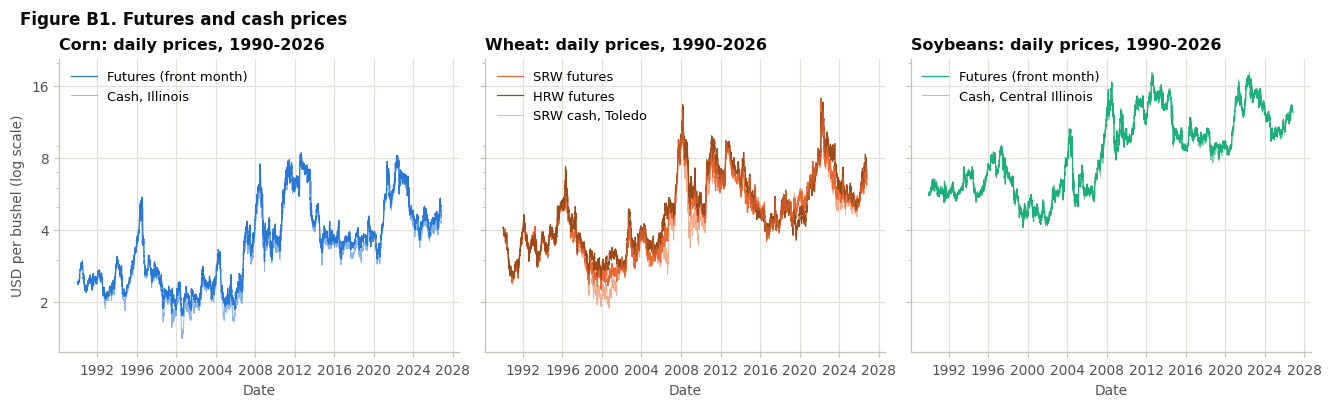

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), constrained_layout=True, sharey=True)
panels = [("Corn", [("corn_fut", "Futures (front month)"), ("corn_cash", "Cash, Illinois")]),
          ("Wheat", [("wheat_fut", "SRW futures"), ("hrw_fut", "HRW futures"), ("wheat_cash", "SRW cash, Toledo")]),
          ("Soybeans", [("soy_fut", "Futures (front month)"), ("soy_cash", "Cash, Central Illinois")])]
for ax, (title, series) in zip(axes, panels):
    for col, label in series:
        y = px[col] / 100 if col in FUT else px[col]       # futures: US cents -> USD per bushel
        ax.plot(y.index, y, lw=0.8 if col in FUT else 0.6, label=label,
                color=COLOR_OF[col], alpha=1.0 if col in FUT else 0.55)
    ax.set_yscale("log")
    ax.set_title(f"{title}: daily prices, 1990-2026", loc="left")
    ax.set_xlabel("Date")
    ax.legend(loc="upper left")
axes[0].set_ylabel("USD per bushel (log scale)")
axes[0].set_yticks([2, 4, 8, 16], ["2", "4", "8", "16"])
axes[0].yaxis.set_minor_formatter(plt.NullFormatter())
fig_title(fig, "Figure B1. Futures and cash prices")
plt.show()

## 4. Time-series properties of daily prices
### 4.1 Return distributions and serial correlation
Daily log returns: futures without roll days, cash prices as reported. Ljung–Box tests (Ljung and Box) check autocorrelation in returns (serial correlation) and in squared returns (volatility clustering, the ARCH effect of Engle).

In [7]:
def ljung_box_p(x, lag=10):
    return acorr_ljungbox(x.dropna(), lags=[lag], return_df=True)["lb_pvalue"].iloc[0]


def return_stats(r, periods_per_year=252):
    """Summary statistics and serial correlation tests of daily log returns (one column per series)."""
    r = r.dropna(how="all")
    return pd.DataFrame({
        "obs": r.count(), "vol_%_pa": 100 * r.std() * np.sqrt(periods_per_year), "skew": r.skew(),
        "excess_kurtosis": r.kurt(), "autocorr_lag1": r.apply(lambda x: x.autocorr(1)),
        "LjungBox_p_returns": r.apply(ljung_box_p),
        "LjungBox_p_squared": r.apply(lambda x: ljung_box_p(x ** 2)),
    }).rename(index=LABELS)


daily = pd.concat([fut_ret_adj, cash_ret], axis=1)
return_stats(daily)

,obs,vol_%_pa,skew,excess_kurtosis,autocorr_lag1,LjungBox_p_returns,LjungBox_p_squared
Corn futures,9090,24.709,-0.014,2.766,0.029,0.075,0.000
SRW wheat futures,9090,29.651,0.259,6.920,0.026,0.229,0.000
HRW wheat futures,9090,27.221,-0.069,2.530,0.050,0.002,0.000
Soybean futures,9016,21.970,-0.215,3.140,0.007,0.000,0.000
Corn cash (Illinois),8573,28.137,-0.271,3.526,-0.005,0.016,0.000
Soybean cash (Illinois),8879,23.293,-0.500,4.514,-0.011,0.013,0.000
SRW wheat cash (Toledo),7048,33.600,0.125,2.514,-0.031,0.019,0.000


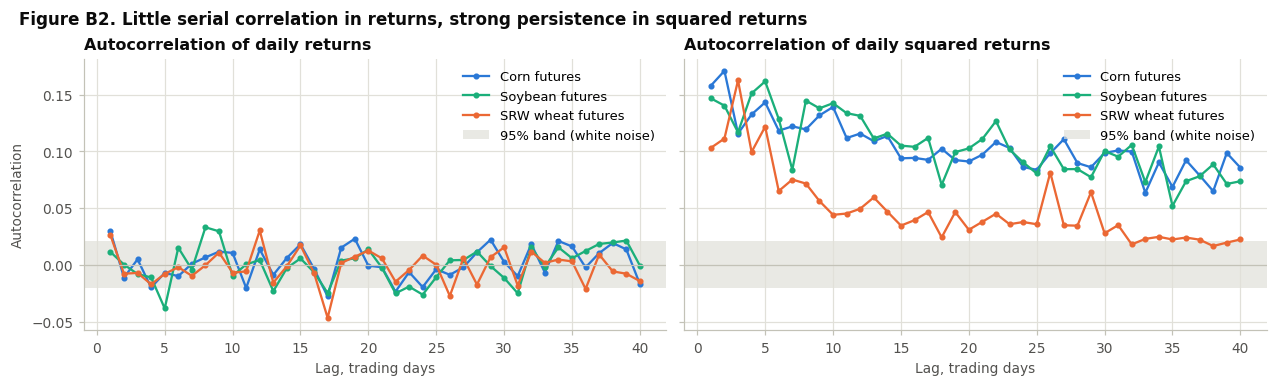

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.4), constrained_layout=True, sharey=True)
lags = np.arange(1, 41)
for ax, (title, power) in zip(axes, [("Returns", 1), ("Squared returns", 2)]):
    for c in ["corn_fut", "soy_fut", "wheat_fut"]:
        x = fut_ret_adj[c].dropna() ** power
        ax.plot(lags, acf(x, nlags=40, fft=True)[1:], marker="o", ms=3, color=COLOR_OF[c], label=LABELS[c])
    band = 1.96 / np.sqrt(fut_ret_adj["corn_fut"].count())
    ax.axhspan(-band, band, color=GRID, alpha=0.7, lw=0, label="95% band (white noise)")
    ax.axhline(0, color=AXIS, lw=0.8)
    ax.set_title(f"Autocorrelation of daily {title.lower()}", loc="left")
    ax.set_xlabel("Lag, trading days")
    ax.legend(loc="upper right")
axes[0].set_ylabel("Autocorrelation")
fig_title(fig, "Figure B2. Little serial correlation in returns, strong persistence in squared returns")
plt.show()

### 4.2 Mean reversion
- **Variance ratios** (Lo and MacKinlay): $VR(q) = \mathrm{Var}(r_t + \dots + r_{t-q+1}) / (q\,\mathrm{Var}(r_t))$ for $q$ = 5, 20, 60, 250 days; $VR < 1$ means mean reversion, $VR > 1$ momentum; heteroskedasticity-robust $p$-values.
- **Price levels:** ADF and KPSS tests (Kwiatkowski et al.) on month-end log prices, 1990–2025, and the AR(1) half-life of the log price.

In [9]:
def variance_ratio(r, q):
    """Lo-MacKinlay VR(q) from overlapping q-day returns, with the heteroskedasticity-robust z* p-value."""
    r = np.asarray(r.dropna(), dtype=float)
    n, mu = len(r), r.mean()
    e = r - mu
    vr = ((np.convolve(r, np.ones(q), "valid") - q * mu) ** 2).sum() / (q * (n - q + 1) * (1 - q / n)) / ((e ** 2).sum() / (n - 1))
    delta = [n * (e[j:] ** 2 * e[:-j] ** 2).sum() / (e ** 2).sum() ** 2 for j in range(1, q)]
    theta = sum((2 * (q - j) / q) ** 2 * d for j, d in zip(range(1, q), delta))
    return vr, 2 * stats.norm.sf(abs((vr - 1) / np.sqrt(theta / n)))


HORIZONS = {5: "1 week", 20: "1 month", 60: "1 quarter", 250: "1 year"}
vr_table = pd.DataFrame({LABELS[c]: {f"{k} ({label})": v for q, label in HORIZONS.items()
                                     for k, v in zip(["VR", "p"], variance_ratio(daily[c], q))}
                         for c in daily}).T
print("Variance ratios of daily returns (VR < 1: mean reversion)")
display(vr_table)


def ar1_half_life(x):
    """Half-life (periods) from the AR(1) regression dx_t = a + b x_{t-1}."""
    dx = x.diff().dropna()
    b = sm.OLS(dx, sm.add_constant(x.shift(1).loc[dx.index])).fit().params.iloc[1]
    return hl_from_lambda(b)


month_end = np.log(px.resample("ME").last()).loc[:f"{LAST_YEAR}-12"]
levels = pd.DataFrame({LABELS[c]: {
    "months": month_end[c].count(),
    "ADF_p_constant": adfuller(month_end[c].dropna(), regression="c", autolag="AIC")[1],
    "ADF_p_trend": adfuller(month_end[c].dropna(), regression="ct", autolag="AIC")[1],
    "KPSS_p": kpss(month_end[c].dropna(), regression="c", nlags="auto")[1],
    "AR1_half_life_months": ar1_half_life(month_end[c].dropna())} for c in month_end}).T
print("Unit-root tests on month-end log prices, 1990-2025 (KPSS p-values are reported within [0.01, 0.10])")
display(levels)

Variance ratios of daily returns (VR < 1: mean reversion)


,VR (1 week),p (1 week),VR (1 month),p (1 month),VR (1 quarter),p (1 quarter),VR (1 year),p (1 year)
Corn futures,1.031,0.311,1.017,0.802,1.081,0.482,1.086,0.696
SRW wheat futures,1.021,0.527,0.975,0.722,0.861,0.231,0.781,0.317
HRW wheat futures,1.066,0.025,1.043,0.500,0.995,0.963,0.998,0.993
Soybean futures,1.008,0.783,0.994,0.931,0.969,0.792,0.931,0.758
Corn cash (Illinois),0.995,0.864,1.072,0.296,1.281,0.018,1.151,0.500
Soybean cash (Illinois),0.980,0.541,1.062,0.373,1.151,0.200,0.978,0.922
SRW wheat cash (Toledo),0.913,0.012,0.872,0.090,0.778,0.084,0.814,0.460


Unit-root tests on month-end log prices, 1990-2025 (KPSS p-values are reported within [0.01, 0.10])


,months,ADF_p_constant,ADF_p_trend,KPSS_p,AR1_half_life_months
Corn futures,432.000,0.129,0.050,0.010,31.543
HRW wheat futures,432.000,0.148,0.129,0.010,26.680
SRW wheat futures,432.000,0.269,0.247,0.010,24.727
Soybean futures,432.000,0.379,0.296,0.010,37.430
Corn cash (Illinois),408.000,0.247,0.207,0.010,34.046
Soybean cash (Illinois),431.000,0.416,0.241,0.010,34.877
SRW wheat cash (Toledo),337.000,0.348,0.176,0.010,24.596


### 4.3 ARIMA
ARMA$(p,q)$ with $p, q \le 2$ chosen by AIC on daily returns (ARIMA$(p,1,q)$ on log prices). Monthly-average and month-end returns are compared, because averaging alone creates autocorrelation of about 0.25 (Working).

In [10]:
def best_arma(r, max_p=2, max_q=2, lb_lag=20):
    """Select ARMA(p,q) with a constant by AIC; Ljung-Box test on the residuals."""
    best, order = None, None
    for p in range(max_p + 1):
        for q in range(max_q + 1):
            try:
                res = ARIMA(r.values, order=(p, 0, q), trend="c").fit()
            except Exception:
                continue
            if best is None or res.aic < best.aic:
                best, order = res, (p, q)
    coefs = ", ".join(f"{n}={v:.2f}" for n, v in zip(best.param_names, best.params) if n.startswith(("ar", "ma")))
    return {"selected": f"ARMA{order}", "AIC": best.aic, "coefficients": coefs or "none (white noise)",
            f"LjungBox_p_lag{lb_lag}": acorr_ljungbox(best.resid, lags=[lb_lag], return_df=True)["lb_pvalue"].iloc[0]}


print("Daily futures returns (percent, roll days removed)")
display(pd.DataFrame({LABELS[c]: best_arma(100 * fut_ret_adj[c].dropna()) for c in FUT}).T)

# Working (1960) effect: monthly-average vs month-end returns of the index without roll gaps
avg_ret = fut_index.resample("ME").mean().diff().loc[:f"{LAST_YEAR}-12"].dropna()   # fut_index is already in logs
end_ret = fut_index.resample("ME").last().diff().loc[:f"{LAST_YEAR}-12"].dropna()
averaging = pd.DataFrame({
    "autocorr_lag1_average_1990+": avg_ret.apply(lambda x: x.autocorr(1)),
    "autocorr_lag1_month_end_1990+": end_ret.apply(lambda x: x.autocorr(1)),
    "autocorr_lag1_average_2014+": avg_ret.loc["2014":].apply(lambda x: x.autocorr(1)),
    "autocorr_lag1_month_end_2014+": end_ret.loc["2014":].apply(lambda x: x.autocorr(1)),
}).rename(index=LABELS)
print("Lag-1 autocorrelation of monthly futures returns: monthly averages vs month-end prices")
display(averaging)
print("ARMA on monthly returns of month-end prices, 1990-2025 (percent)")
display(pd.DataFrame({LABELS[c]: best_arma(100 * end_ret[c], lb_lag=12) for c in FUT}).T)

Daily futures returns (percent, roll days removed)


,selected,AIC,coefficients,LjungBox_p_lag20
Corn futures,"ARMA(1, 1)","33,836.446","ar.L1=-0.56, ma.L1=0.58",0.069
SRW wheat futures,"ARMA(0, 1)","37,153.512",ma.L1=0.03,0.002
HRW wheat futures,"ARMA(0, 1)","35,582.920",ma.L1=0.05,0.053
Soybean futures,"ARMA(0, 0)","31,449.260",none (white noise),0.000


Lag-1 autocorrelation of monthly futures returns: monthly averages vs month-end prices


,autocorr_lag1_average_1990+,autocorr_lag1_month_end_1990+,autocorr_lag1_average_2014+,autocorr_lag1_month_end_2014+
Corn futures,0.290,-0.022,0.303,-0.042
SRW wheat futures,0.176,-0.039,0.069,-0.080
HRW wheat futures,0.227,-0.048,0.153,-0.118
Soybean futures,0.226,-0.077,0.219,-0.043


ARMA on monthly returns of month-end prices, 1990-2025 (percent)


,selected,AIC,coefficients,LjungBox_p_lag12
Corn futures,"ARMA(2, 0)","2,914.946","ar.L1=-0.02, ar.L2=0.14",0.069
SRW wheat futures,"ARMA(2, 0)","3,031.037","ar.L1=-0.04, ar.L2=-0.13",0.579
HRW wheat futures,"ARMA(0, 0)","3,005.283",none (white noise),0.229
Soybean futures,"ARMA(1, 1)","2,825.456","ar.L1=-0.92, ma.L1=0.85",0.118


### 4.4 GARCH
GARCH(1,1) with Student-$t$ errors (Bollerslev) on daily futures returns in percent, $\sigma^2_t = \omega + \alpha\,\varepsilon^2_{t-1} + \beta\,\sigma^2_{t-1}$. The half-life of a volatility shock is $\ln 0.5/\ln(\alpha+\beta)$ trading days. A GJR term (Glosten et al.), $\gamma\,\varepsilon^2_{t-1}\mathbb{1}[\varepsilon_{t-1}<0]$, tests whether falls raise volatility more than rises ($\gamma > 0$) or less ($\gamma < 0$).

In [11]:
garch_rows, garch_fits = {}, {}
for c in FUT:
    x = 100 * fut_ret_adj[c].dropna()
    g = arch_model(x, mean="Constant", vol="GARCH", p=1, q=1, dist="t").fit(disp="off")
    gjr = arch_model(x, mean="Constant", vol="GARCH", p=1, o=1, q=1, dist="t").fit(disp="off")
    a, b = g.params["alpha[1]"], g.params["beta[1]"]
    garch_fits[c] = g
    garch_rows[LABELS[c]] = {
        "omega": g.params["omega"], "alpha": a, "beta": b, "persistence": a + b,
        "vol_half_life_days": np.log(0.5) / np.log(a + b), "t_dof": g.params["nu"],
        "LjungBox_p_squared_std_resid": ljung_box_p(g.std_resid ** 2),
        "GJR_gamma": gjr.params["gamma[1]"], "p(GJR_gamma)": gjr.pvalues["gamma[1]"],
        "AIC_GARCH": g.aic, "AIC_GJR": gjr.aic}
garch_table = pd.DataFrame(garch_rows).T
garch_table

,omega,alpha,beta,persistence,vol_half_life_days,t_dof,LjungBox_p_squared_std_resid,GJR_gamma,p(GJR_gamma),AIC_GARCH,AIC_GJR
Corn futures,0.025,0.071,0.921,0.992,87.837,6.828,0.331,0.008,0.399,"31,850.163","31,851.416"
SRW wheat futures,0.040,0.044,0.944,0.988,56.980,8.746,0.999,-0.034,0.000,"35,532.348","35,504.529"
HRW wheat futures,0.027,0.047,0.944,0.991,78.987,8.572,0.555,-0.034,0.000,"34,230.968","34,203.993"
Soybean futures,0.021,0.059,0.931,0.990,70.581,7.159,0.976,-0.029,0.000,"29,588.194","29,576.003"


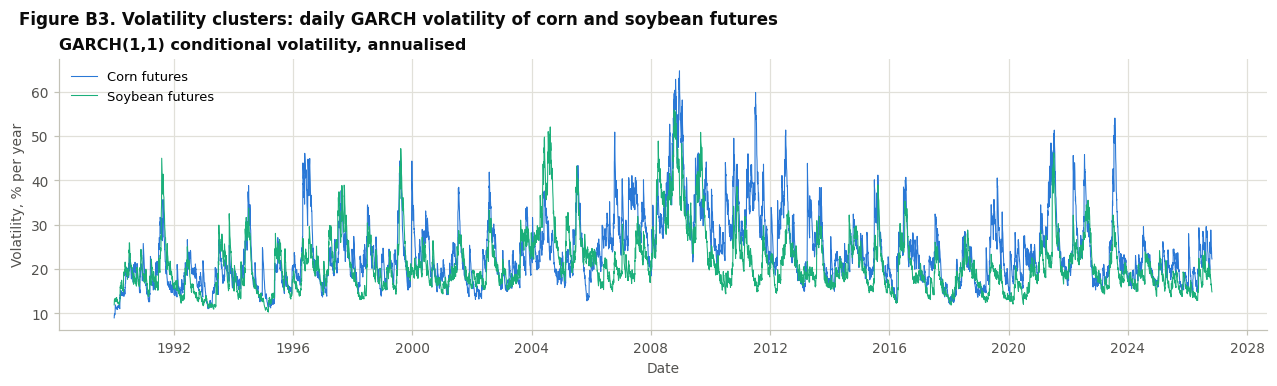

In [12]:
fig, ax = plt.subplots(figsize=(11.5, 3.4), constrained_layout=True)
for c in ["corn_fut", "soy_fut"]:
    vol = garch_fits[c].conditional_volatility * np.sqrt(252)
    ax.plot(vol.index, vol, lw=0.7, color=COLOR_OF[c], label=LABELS[c])
ax.set_title("GARCH(1,1) conditional volatility, annualised", loc="left")
ax.set_ylabel("Volatility, % per year")
ax.set_xlabel("Date")
ax.legend(loc="upper left")
fig_title(fig, "Figure B3. Volatility clusters: daily GARCH volatility of corn and soybean futures")
plt.show()

### 4.5 Seasonality
Annualised realised volatility by calendar month (1990–2025) with an HAC F-test of month effects; the same test on mean returns. Seasonal GARCH: returns are divided by a calendar-month volatility factor before GARCH(1,1) (a two-step approach as in Andersen and Bollerslev); AIC counts the 11 extra parameters.

In [13]:
def month_F_p(y, maxlags):
    """HAC F-test p-value that all calendar-month effects in y are zero."""
    y = y.dropna()
    dummies = pd.get_dummies(y.index.month, prefix="m", drop_first=True).astype(float).set_index(y.index)
    return sm.OLS(y, sm.add_constant(dummies)).fit(cov_type="HAC", cov_kwds={"maxlags": maxlags}).f_pvalue


rv = (fut_ret_adj.loc[:f"{LAST_YEAR}"] ** 2).resample("ME").sum(min_count=10)        # monthly realised variance
vol_by_month = (100 * np.sqrt(12 * rv)).groupby(rv.index.month).mean().rename(columns=LABELS)
vol_by_month.index = [calendar.month_abbr[m] for m in vol_by_month.index]
print("Average annualised volatility by calendar month, % (1990-2025)")
display(vol_by_month.T)

cash_monthly_ret = np.log(px[list(CASH)].resample("ME").mean()).diff().loc[:f"{LAST_YEAR}-12"]
seasonal_tests = pd.DataFrame({
    "volatility_peak_month": vol_by_month.idxmax(),
    "volatility_low_month": vol_by_month.idxmin(),
    "peak_to_low_ratio": vol_by_month.max() / vol_by_month.min(),
    "F_p_month_effects_in_volatility": {LABELS[c]: month_F_p(np.log(rv[c]), 12) for c in FUT},
    "F_p_month_effects_in_daily_returns": {LABELS[c]: month_F_p(fut_ret_adj[c], 20) for c in FUT},
})
seasonal_tests = pd.concat([seasonal_tests, pd.DataFrame(
    {"F_p_month_effects_in_monthly_cash_returns": {LABELS[c]: month_F_p(cash_monthly_ret[c], 12) for c in CASH}})])
display(seasonal_tests)

Average annualised volatility by calendar month, % (1990-2025)


,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
Corn futures,20.040,16.288,21.897,21.135,24.640,29.377,30.488,25.151,22.455,22.471,19.339,18.642
SRW wheat futures,23.837,25.289,31.964,26.604,31.615,30.477,29.976,28.140,25.653,26.967,24.359,23.466
HRW wheat futures,22.769,22.761,27.278,25.505,30.473,28.106,27.505,25.717,23.884,23.866,23.123,22.941
Soybean futures,18.547,15.725,18.830,18.021,19.927,23.323,26.049,25.353,20.662,20.281,18.763,16.378


,volatility_peak_month,volatility_low_month,peak_to_low_ratio,F_p_month_effects_in_volatility,F_p_month_effects_in_daily_returns,F_p_month_effects_in_monthly_cash_returns
Corn futures,Jul,Feb,1.872,0.000,0.007,NaN
SRW wheat futures,Mar,Dec,1.362,0.000,0.947,NaN
HRW wheat futures,May,Feb,1.339,0.000,0.987,NaN
Soybean futures,Jul,Feb,1.657,0.000,0.456,NaN
Corn cash (Illinois),NaN,NaN,NaN,NaN,NaN,0.000
Soybean cash (Illinois),NaN,NaN,NaN,NaN,NaN,0.000
SRW wheat cash (Toledo),NaN,NaN,NaN,NaN,NaN,0.149


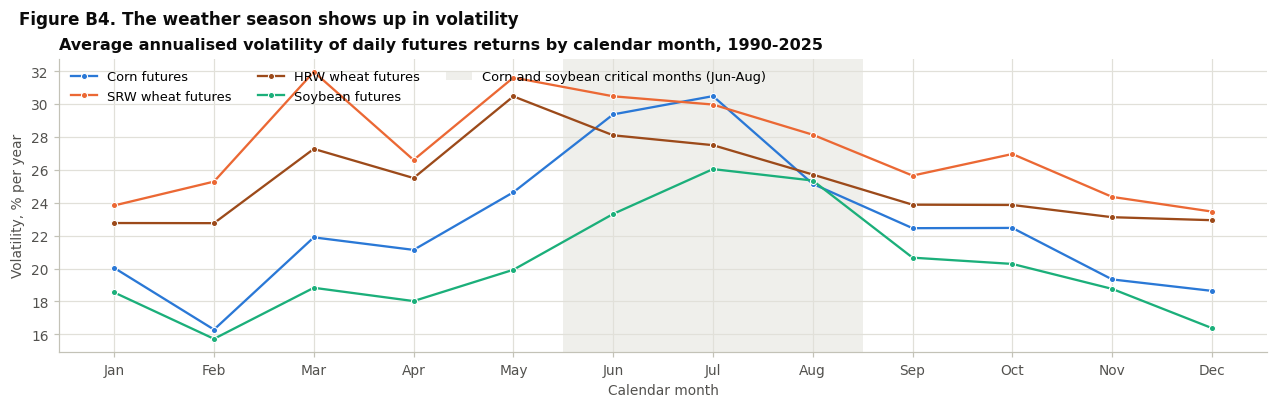

In [14]:
fig, ax = plt.subplots(figsize=(11.5, 3.6), constrained_layout=True)
for c in FUT:
    ax.plot(range(1, 13), vol_by_month[LABELS[c]], marker="o", ms=4, mec="white", mew=0.7,
            color=COLOR_OF[c], label=LABELS[c])
ax.axvspan(5.5, 8.5, color=GRID, alpha=0.5, lw=0, label="Corn and soybean critical months (Jun-Aug)")
ax.set_xticks(range(1, 13), [calendar.month_abbr[m] for m in range(1, 13)])
ax.set_title("Average annualised volatility of daily futures returns by calendar month, 1990-2025", loc="left")
ax.set_xlabel("Calendar month")
ax.set_ylabel("Volatility, % per year")
ax.legend(loc="upper left", ncol=3)
fig_title(fig, "Figure B4. The weather season shows up in volatility")
plt.show()

In [15]:
def month_F_p_z2(z):
    return month_F_p(z ** 2, 20)


seasonal_garch = {}
for c in FUT:
    x = 100 * fut_ret_adj[c].dropna()
    plain = garch_fits[c]
    factor = (x ** 2).groupby(x.index.month).mean() / (x ** 2).mean()    # calendar-month variance factor
    s = x.index.month.map(factor).to_numpy()
    seas = arch_model(x / np.sqrt(s), mean="Constant", vol="GARCH", p=1, q=1, dist="t").fit(disp="off")
    loglik = seas.loglikelihood - 0.5 * np.log(s).sum()                    # back to the scale of x
    seasonal_garch[LABELS[c]] = {
        "AIC_plain": plain.aic, "AIC_seasonal": -2 * loglik + 2 * (len(seas.params) + 11),
        "month_F_p_in_z2_plain": month_F_p_z2(plain.std_resid.dropna()),
        "month_F_p_in_z2_seasonal": month_F_p_z2(seas.std_resid.dropna()),
        "persistence_plain": plain.params["alpha[1]"] + plain.params["beta[1]"],
        "persistence_seasonal": seas.params["alpha[1]"] + seas.params["beta[1]"],
        "peak_month": calendar.month_abbr[factor.idxmax()], "low_month": calendar.month_abbr[factor.idxmin()],
        "vol_ratio_peak_to_low": np.sqrt(factor.max() / factor.min())}
pd.DataFrame(seasonal_garch).T

,AIC_plain,AIC_seasonal,month_F_p_in_z2_plain,month_F_p_in_z2_seasonal,persistence_plain,persistence_seasonal,peak_month,low_month,vol_ratio_peak_to_low
Corn futures,"31,850.163","31,782.915",0.000,0.618,0.992,0.993,Jul,Feb,1.766
SRW wheat futures,"35,532.348","35,545.512",0.033,0.890,0.988,0.991,Mar,Dec,1.465
HRW wheat futures,"34,230.968","34,224.830",0.005,0.935,0.991,0.995,May,Jan,1.345
Soybean futures,"29,588.194","29,556.506",0.000,0.900,0.990,0.992,Jul,Dec,1.643


## 5. Weather and prices with daily data, 1990–2025
Season return: the sum of daily futures log returns (roll days removed) over each crop's weather window, with the weather points of the main notebook (Section 7); for corn and soybeans also the season change of the Illinois cash price. Each is regressed on the yield deviation from trend, on season weather, and by 2SLS (robust first-stage $F$; Anderson–Rubin test, Anderson and Rubin). The last columns test if larger weather anomalies raise season volatility. Robust (`HC1`) standard errors.

In [16]:
weather = pd.read_csv(DATA_DIR / "nasa_power_monthly.csv", index_col=0, parse_dates=True)
psd = pd.read_csv(DATA_DIR / "usda_psd_us_eu.csv")
yields = (psd[psd["Attribute_Description"] == "Yield"]
          .pivot_table(index="Market_Year", columns=["region", "crop"], values="Value").loc[:LAST_YEAR])

WINDOWS = {   # crop: (futures, cash price or None, weather points, months) - as in the main notebook, Section 7
    "corn": ("corn_fut", "corn_cash", ["US_Iowa", "US_Illinois"], [6, 7, 8]),
    "soybeans": ("soy_fut", "soy_cash", ["US_Iowa", "US_Illinois"], [7, 8]),
    "wheat": ("hrw_fut", None, ["US_Kansas", "US_Illinois"], [4, 5, 6]),
}


def yield_deviation(crop):
    """% deviation of US yield from its log-linear trend over 1981-2025 (as in the main notebook)."""
    y = np.log(yields[("US", crop)].loc[1981:])
    return 100 * sm.OLS(y, sm.add_constant(np.arange(len(y), dtype=float))).fit().resid


def season_weather(sites, months):
    """Season mean temperature (deg C) and season total precipitation (mm), averaged over the weather points."""
    s = weather[weather["site"].isin(sites) & weather.index.month.isin(months)]
    return pd.DataFrame({"tmean": s.groupby(s.index.year)["tmean"].mean(),
                         "prcp": s.groupby([s.index.year, "site"])["prcp"].sum().groupby(level=0).mean()})


def season_change(log_price, months):
    """100 x change in mean log price, from the 3 months before the weather window to the 3 months after it."""
    out = {}
    for year in range(log_price.index.year.min() + 1, LAST_YEAR + 1):
        pre = pd.date_range(pd.Timestamp(year, months[0], 1) - pd.DateOffset(months=3), periods=3, freq="ME")
        post = pd.date_range(pd.Timestamp(year, months[-1], 1) + pd.DateOffset(months=1), periods=3, freq="ME")
        if pre.isin(log_price.index).all() and post.isin(log_price.index).all():
            out[year] = 100 * (log_price[post].mean() - log_price[pre].mean())
    return pd.Series(out, dtype=float)


def tsls(y, x, Z):
    """2SLS slope of y on one endogenous regressor x, instruments Z (with constant); HC1 standard error."""
    Xh = sm.add_constant(sm.OLS(x, Z).fit().fittedvalues.rename("x"))
    b = np.linalg.lstsq(Xh, y, rcond=None)[0]
    u = (y - sm.add_constant(x.rename("x")) @ b).values
    n, k = Xh.shape
    bread = np.linalg.inv(Xh.T @ Xh)
    meat = (Xh.values * u[:, None]).T @ (Xh.values * u[:, None]) * n / (n - k)
    se = np.sqrt((bread @ meat @ bread)[1, 1])
    return b[1], 2 * stats.t.sf(abs(b[1] / se), n - k)


def weather_price_row(dp, crop, sites, months):
    """OLS on the yield deviation, reduced form on weather, and 2SLS with instruments T, T^2, P, P^2."""
    w = season_weather(sites, months).loc[1981:LAST_YEAR]
    z = (w - w.mean()) / w.std()                                          # standardised as in the main notebook
    Z = pd.DataFrame({"T": z["tmean"], "T2": z["tmean"] ** 2, "P": z["prcp"], "P2": z["prcp"] ** 2})
    df = pd.concat([dp.rename("dp"), yield_deviation(crop).rename("dev"), w, Z], axis=1).dropna()
    ols = sm.OLS(df["dp"], sm.add_constant(df["dev"])).fit(cov_type="HC1")
    reduced = sm.OLS(df["dp"], sm.add_constant(df[["tmean", "prcp"]])).fit(cov_type="HC1")
    first = sm.OLS(df["dev"], sm.add_constant(df[Z.columns])).fit(cov_type="HC1")
    anderson_rubin = sm.OLS(df["dp"], sm.add_constant(df[Z.columns])).fit(cov_type="HC1")
    b_iv, p_iv = tsls(df["dp"], df["dev"], sm.add_constant(df[Z.columns]))
    return df, {"years": f"{df.index.min()}-{df.index.max()}", "n": len(df), "R2_yield": ols.rsquared,
                "price_%_per_1%_yield": ols.params["dev"], "p": ols.pvalues["dev"],
                "price_%_per_+1C": reduced.params["tmean"], "p(+1C)": reduced.pvalues["tmean"],
                "2SLS_price_%_per_1%_yield": b_iv, "p(2SLS)": p_iv,
                "first_stage_F_robust": first.fvalue, "Anderson_Rubin_p": anderson_rubin.f_pvalue}


rows, scatter = {}, {}
for crop, (fut, cash, sites, months) in WINDOWS.items():
    r = fut_ret_adj[fut].loc[:f"{LAST_YEAR}"]
    in_season = r[r.index.month.isin(months)]
    season_return = 100 * in_season.groupby(in_season.index.year).sum()
    df, row = weather_price_row(season_return, crop, sites, months)
    # does a bigger weather anomaly raise volatility in the season?
    vol = np.log(100 * np.sqrt(252 * (in_season ** 2).groupby(in_season.index.year).mean()))
    anomaly = pd.DataFrame({"abs_T": df["T"].abs(), "abs_P": df["P"].abs()})
    vfit = sm.OLS(vol.loc[df.index], sm.add_constant(anomaly)).fit(cov_type="HC1")
    row.update({"vol_p(|T|)": vfit.pvalues["abs_T"], "vol_p(|P|)": vfit.pvalues["abs_P"]})
    rows[f"{crop}: {LABELS[fut]}, season return"] = row
    scatter[crop] = df
    if cash:
        dp = season_change(np.log(px[cash].resample("ME").mean().dropna()), months)
        rows[f"{crop}: {LABELS[cash]}, season change"] = weather_price_row(dp, crop, sites, months)[1]
weather_prices = pd.DataFrame(rows).T
weather_prices

,years,n,R2_yield,price_%_per_1%_yield,p,price_%_per_+1C,p(+1C),2SLS_price_%_per_1%_yield,p(2SLS),first_stage_F_robust,Anderson_Rubin_p,vol_p(|T|),vol_p(|P|)
"corn: Corn futures, season return",1990-2025,36,0.488,-1.343,0.000,6.334,0.002,-1.562,0.000,9.274,0.000,0.281,0.450
"corn: Corn cash (Illinois), season change",1993-2025,33,0.230,-1.379,0.000,12.835,0.000,-1.860,0.016,7.380,0.001,NaN,NaN
"soybeans: Soybean futures, season return",1990-2025,36,0.250,-0.671,0.002,2.310,0.023,-1.239,0.007,4.673,0.000,0.706,0.221
"soybeans: Soybean cash (Illinois), season change",1991-2025,35,0.110,-0.953,0.004,7.164,0.001,-2.922,0.027,4.459,0.008,NaN,NaN
"wheat: HRW wheat futures, season return",1990-2025,36,0.241,-1.046,0.000,3.126,0.124,-7.128,0.452,0.104,0.009,0.684,0.244


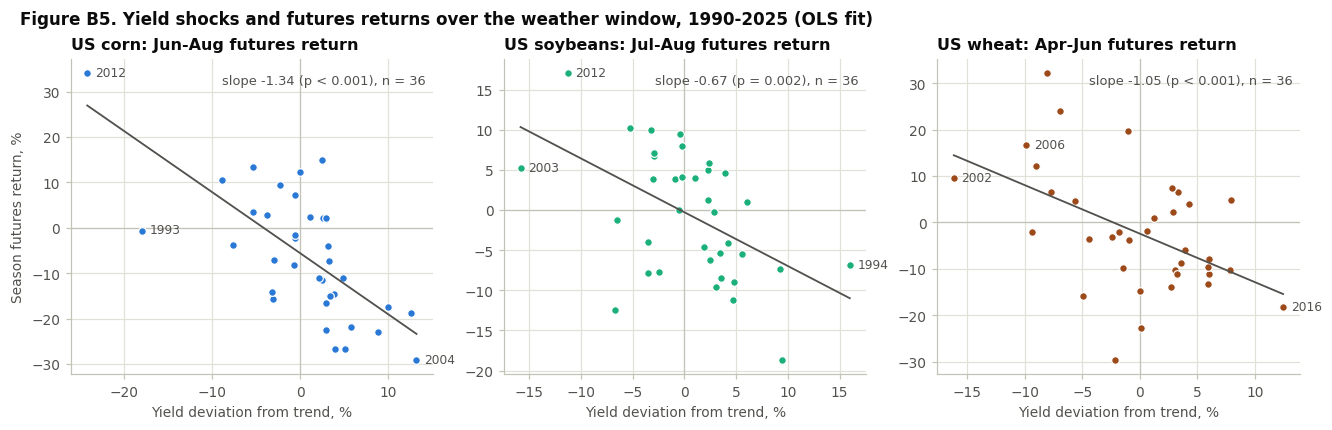

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), constrained_layout=True)
for ax, (crop, color) in zip(axes, [("corn", COLORS["corn"]), ("soybeans", COLORS["soy"]), ("wheat", COLORS["hrw"])]):
    df = scatter[crop]
    fit = sm.OLS(df["dp"], sm.add_constant(df["dev"])).fit(cov_type="HC1")
    grid = np.linspace(df["dev"].min(), df["dev"].max(), 50)
    ax.axhline(0, color=AXIS, lw=0.8)
    ax.axvline(0, color=AXIS, lw=0.8)
    ax.plot(df["dev"], df["dp"], "o", ms=5, color=color, mec="white", mew=0.8)
    ax.plot(grid, fit.params["const"] + fit.params["dev"] * grid, color=INK2, lw=1.2)
    for year in df["dev"].abs().nlargest(3).index:
        ax.annotate(str(year), (df.loc[year, "dev"], df.loc[year, "dp"]), xytext=(5, -2),
                    textcoords="offset points", color=INK2, fontsize=8)
    months = WINDOWS[crop][3]
    ax.set_title(f"US {crop}: {calendar.month_abbr[months[0]]}-{calendar.month_abbr[months[-1]]} futures return",
                 loc="left")
    p = fit.pvalues["dev"]
    ax.text(0.98, 0.95, f"slope {fit.params['dev']:.2f} ({'p < 0.001' if p < 0.001 else f'p = {p:.3f}'}), n = {len(df)}",
            transform=ax.transAxes, ha="right", va="top", color=INK2, fontsize=8.5)
    ax.set_xlabel("Yield deviation from trend, %")
axes[0].set_ylabel("Season futures return, %")
fig_title(fig, "Figure B5. Yield shocks and futures returns over the weather window, 1990-2025 (OLS fit)")
plt.show()

## 6. Corn and wheat over 36 years (CBOT)
Weekly front-month SRW wheat and corn (both roll on the same days), 1990–2026 and by decade, with the main notebook's methods: Engle–Granger and Johansen tests (Engle and Granger; Johansen; 5% critical values of the trace statistics 15.5 for $r = 0$ and 3.8 for $r \le 1$), the ECM with HAC errors (Newey and West), single and system half-lives, and direct tests of equal speed and of an equal hedge ratio (dynamic OLS, Stock and Watson) before and after 2020.

In [18]:
def coint_decision(eg_p, rank):
    """Main notebook rule: cointegrated if both tests reject at 5%, not cointegrated if neither does, else mixed."""
    if eg_p < 0.05 and rank == 1:
        return "cointegrated"
    if eg_p >= 0.05 and rank == 0:
        return "not cointegrated"
    return "mixed (conditional)"


def ecm_data(df, y, x, max_lags):
    """Log prices, hedge ratio, lag order, ECM regressors [const, ECT(-1), lagged changes] and targets."""
    d = np.log(df[[y, x]].dropna())
    beta = sm.OLS(d[y], sm.add_constant(d[x])).fit().params[x]
    ect = d[y] - beta * d[x]
    p = max(1, select_order(d, maxlags=max_lags, deterministic="ci").aic)
    dd = d.diff()
    X = pd.DataFrame({"const": 1.0, "ECT_lag": ect.shift(1)})
    for i in range(1, p + 1):
        X[f"dy_lag{i}"], X[f"dx_lag{i}"] = dd[y].shift(i), dd[x].shift(i)
    return d, beta, p, X, {"y": dd[y], "x": dd[x], "ECT": ect.diff()}


def fit_ecm(target, X):
    """OLS with HAC (Newey-West) standard errors."""
    data = pd.concat([target.rename("target"), X], axis=1).dropna()
    return sm.OLS(data["target"], data.drop(columns="target")).fit(cov_type="HAC",
                                                                    cov_kwds={"maxlags": nw_lags(len(data))})


def system_half_life(fits, beta, p, horizon=1000):
    """Periods until a one-unit equilibrium error first halves when both ECM equations run together."""
    dy, dx = np.zeros(horizon + p), np.zeros(horizon + p)
    ect = 1.0
    for t in range(p, horizon + p):
        for k, store in (("y", dy), ("x", dx)):
            b = fits[k].params
            store[t] = b["ECT_lag"] * ect + sum(b[f"dy_lag{i}"] * dy[t - i] + b[f"dx_lag{i}"] * dx[t - i]
                                                for i in range(1, p + 1))
        new = ect + dy[t] - beta * dx[t]
        if new <= 0.5:
            return t - p + (ect - 0.5) / (ect - new)
        ect = new
    return np.inf


def pair_tests(df, y, x, max_lags=8, per_month=WEEKS_PER_MONTH):
    """Cointegration tests, ECM adjustment and half-lives for one pair and sample (the main notebook's methods)."""
    d, beta, p, X, targets = ecm_data(df, y, x, max_lags)
    eg_p = coint(d[y], d[x], trend="c", autolag="aic")[1]
    jo = coint_johansen(d, det_order=0, k_ar_diff=p)
    rank = int(np.cumprod(jo.lr1 > jo.cvt[:, 1]).sum())
    fits = {k: fit_ecm(t, X) for k, t in targets.items()}
    lam, pval = {k: f.params["ECT_lag"] for k, f in fits.items()}, {k: f.pvalues["ECT_lag"] for k, f in fits.items()}
    low, high = fits["ECT"].conf_int().loc["ECT_lag"]
    adjusting = [LABELS[c] for c, k, sign in [(y, "y", -1), (x, "x", 1)] if pval[k] < 0.05 and sign * lam[k] > 0]
    return {"sample": f"{d.index.min():%Y-%m} to {d.index.max():%Y-%m}", "obs": len(d), "beta": beta,
            "EG_p": eg_p, "Johansen_trace_r0": jo.lr1[0], "Johansen_trace_r1": jo.lr1[1], "Johansen_rank": rank,
            "decision": coint_decision(eg_p, rank),
            "adjusting_price": ", ".join(adjusting) or "none at 5%",
            "lambda_ECT": lam["ECT"], "p(lambda_ECT)": pval["ECT"], "se(lambda_ECT)": fits["ECT"].bse["ECT_lag"],
            "half_life_months": hl_from_lambda(lam["ECT"]) / per_month,
            "hl_95%_months": f"{hl_from_lambda(low) / per_month:.1f} to {hl_from_lambda(high) / per_month:.1f}",
            "system_half_life_months": system_half_life(fits, beta, p) / per_month,
            "log_ratio_half_life_months": ar1_half_life(d[y] - d[x]) / per_month}


def dols_break(df, y, x, break_date, k=2):
    """Dynamic OLS (Stock and Watson) of ln y on ln x with k leads and lags of the change in ln x and a shift in
    intercept and slope from break_date. Returns the hedge ratio before and after, and the HAC p-value of the shift."""
    d = np.log(df[[y, x]].dropna())
    post = (d.index >= pd.Timestamp(break_date)).astype(float)
    X = pd.DataFrame({"const": 1.0, "x": d[x], "post": post, "post_x": post * d[x]}, index=d.index)
    dx = d[x].diff()
    for j in range(-k, k + 1):
        X[f"dx_{j}"] = dx.shift(j)
    data = pd.concat([d[y].rename("y"), X], axis=1).dropna()
    fit = sm.OLS(data["y"], data.drop(columns="y")).fit(cov_type="HAC", cov_kwds={"maxlags": nw_lags(len(data))})
    return fit.params["x"], fit.params["x"] + fit.params["post_x"], fit.pvalues["post_x"]


weekly_fut = px[FUT].resample("W-FRI").last()
PERIODS = {"1990-2026": ("1990", "2026"), "1990-1999": ("1990", "1999"), "2000-2009": ("2000", "2009"),
           "2010-2019": ("2010", "2019"), "1990-2019 (before 2020)": ("1990", "2019"), "2020-2026": ("2020", "2026")}
long_sample = pd.DataFrame({name: pair_tests(weekly_fut.loc[a:b], "wheat_fut", "corn_fut")
                            for name, (a, b) in PERIODS.items()}).T
long_sample

,sample,obs,beta,EG_p,Johansen_trace_r0,Johansen_trace_r1,Johansen_rank,decision,adjusting_price,lambda_ECT,p(lambda_ECT),se(lambda_ECT),half_life_months,hl_95%_months,system_half_life_months,log_ratio_half_life_months
1990-2026,1990-01 to 2026-10,1922,0.859,0.000,48.890,5.152,2,mixed (conditional),Corn futures,-0.036,0.000,0.008,4.409,3.0 to 8.2,4.475,4.502
1990-1999,1990-01 to 1999-12,522,0.848,0.076,17.491,3.917,2,mixed (conditional),Corn futures,-0.033,0.004,0.011,4.746,2.8 to 14.7,4.878,4.066
2000-2009,2000-01 to 2009-12,521,1.064,0.020,21.277,2.621,1,cointegrated,Corn futures,-0.045,0.002,0.015,3.451,2.1 to 9.7,2.965,4.567
2010-2019,2010-01 to 2019-12,522,0.692,0.014,18.494,2.790,1,cointegrated,SRW wheat futures,-0.056,0.000,0.014,2.793,1.8 to 5.6,2.694,4.545
1990-2019 (before 2020),1990-01 to 2019-12,1565,0.856,0.000,38.225,4.885,2,mixed (conditional),Corn futures,-0.031,0.000,0.009,5.109,3.3 to 11.4,5.131,5.178
2020-2026,2020-01 to 2026-10,357,0.710,0.015,17.776,2.985,1,cointegrated,SRW wheat futures,-0.085,0.000,0.024,1.810,1.1 to 4.1,1.919,2.221


In [19]:
pre, post = long_sample.loc["1990-2019 (before 2020)"], long_sample.loc["2020-2026"]
z = (pre["lambda_ECT"] - post["lambda_ECT"]) / np.hypot(pre["se(lambda_ECT)"], post["se(lambda_ECT)"])
beta_pre, beta_post, p_beta = dols_break(weekly_fut, "wheat_fut", "corn_fut", "2020-01-01")
pd.Series({"ECT half-life before 2020, months": pre["half_life_months"],
           "ECT half-life from 2020, months": post["half_life_months"],
           "p, equal adjustment speed": 2 * stats.norm.sf(abs(z)),
           "DOLS hedge ratio before 2020": beta_pre, "DOLS hedge ratio from 2020": beta_post,
           "p, equal hedge ratio": p_beta}, name="US wheat~corn, weekly, 1990-2026").to_frame()

,"US wheat~corn, weekly, 1990-2026"
"ECT half-life before 2020, months",5.109
"ECT half-life from 2020, months",1.810
"p, equal adjustment speed",0.032
DOLS hedge ratio before 2020,0.858
DOLS hedge ratio from 2020,0.717
"p, equal hedge ratio",0.073


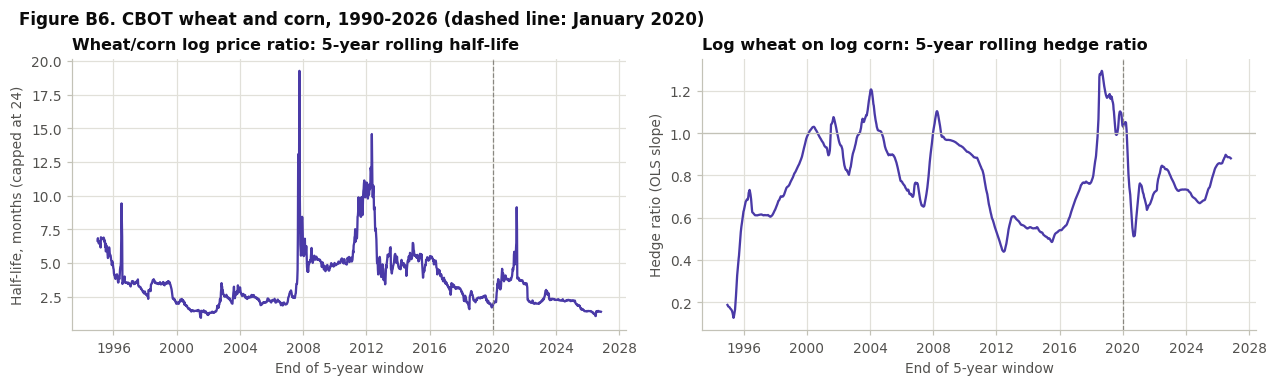

In [20]:
def rolling_half_life(s, window):
    """Half-life (periods) of an AR(1) fitted in a rolling window; NaN where the window shows no mean reversion."""
    lag, ds = s.shift(1), s.diff()
    b = ds.rolling(window).cov(lag) / lag.rolling(window).var()
    return (np.log(2) / -np.log(1 + b)).where((b < 0) & (b > -1))


WINDOW = 260   # five years of weekly data
lw = np.log(weekly_fut[["wheat_fut", "corn_fut"]].dropna())
hl = rolling_half_life(lw["wheat_fut"] - lw["corn_fut"], WINDOW) / WEEKS_PER_MONTH
beta_roll = lw["wheat_fut"].rolling(WINDOW).cov(lw["corn_fut"]) / lw["corn_fut"].rolling(WINDOW).var()

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.4), constrained_layout=True)
axes[0].plot(hl.clip(upper=24), color=REGION["US"])
axes[0].set_ylabel("Half-life, months (capped at 24)")
axes[0].set_title("Wheat/corn log price ratio: 5-year rolling half-life", loc="left")
axes[1].plot(beta_roll, color=REGION["US"])
axes[1].axhline(1, color=AXIS, lw=0.8)
axes[1].set_ylabel("Hedge ratio (OLS slope)")
axes[1].set_title("Log wheat on log corn: 5-year rolling hedge ratio", loc="left")
for ax in axes:
    ax.axvline(pd.Timestamp("2020-01-01"), color=MUTED, lw=0.8, ls="--")
    ax.set_xlabel("End of 5-year window")
fig_title(fig, "Figure B6. CBOT wheat and corn, 1990-2026 (dashed line: January 2020)")
plt.show()

## 7. US vs EU with matched cash prices
Both regions with cash prices: weekly averages of USDA daily prices (Toledo SRW wheat, Illinois corn; USD/t) against EU-average weekly prices (EUR/t), on the main notebook's common weeks. Speed test with Driscoll–Kraay errors (Driscoll and Kraay). The US cash pair is not from one location.

In [21]:
def speed_test(parts, per_month):
    """parts: {"US": (target, X), "EU": (target, X)}. Stacked OLS on common dates with Driscoll-Kraay standard errors."""
    data = {k: pd.concat([t.rename("target"), X], axis=1).dropna() for k, (t, X) in parts.items()}
    dates = data["US"].index.intersection(data["EU"].index)
    Y = pd.concat([d.loc[dates, "target"] for d in data.values()], ignore_index=True)
    X = pd.concat([d.loc[dates].drop(columns="target").add_prefix(f"{k}_") for k, d in data.items()],
                  ignore_index=True).fillna(0.0)                       # block diagonal: one block per region
    time_index = np.tile(np.arange(len(dates)), 2)
    res = sm.OLS(Y, X).fit(cov_type="hac-groupsum", cov_kwds={"time": time_index, "maxlags": nw_lags(len(dates))})
    contrast = (X.columns == "US_ECT_lag").astype(float) - (X.columns == "EU_ECT_lag").astype(float)
    test = res.t_test(contrast)
    low, high = np.asarray(test.conf_int()).ravel()
    lam_us, lam_eu = res.params["US_ECT_lag"], res.params["EU_ECT_lag"]
    return {"obs_per_region": len(dates), "half_life_US_months": hl_from_lambda(lam_us) / per_month,
            "half_life_EU_months": hl_from_lambda(lam_eu) / per_month,
            "lambda_US_minus_EU_95%": f"{low:+.3f} to {high:+.3f}", "p_equal_speed": float(test.pvalue)}


def ecm_system(df, y, x, max_lags=8):
    _, _, _, X, targets = ecm_data(df, y, x, max_lags)
    return targets["ECT"], X


BU_PER_TONNE = pd.Series({"corn_cash": 39.3683, "wheat_cash": 36.7437})   # USD/bu -> USD/t
us_cash_weekly = (px[["wheat_cash", "corn_cash"]] * BU_PER_TONNE).resample("W-FRI").mean()
eu_weekly = pd.read_csv(DATA_DIR / "eu_cereals_weekly.csv", index_col=0, parse_dates=True)
eu_weekly = eu_weekly.resample("W-FRI").last().ffill(limit=2)              # as in the main notebook
cash_weekly = pd.concat([us_cash_weekly, eu_weekly, weekly_fut[["wheat_fut", "corn_fut"]]], axis=1)
cash_weekly = cash_weekly.loc[eu_weekly.index.min():EU_LAST_WEEK].dropna()

matched = pd.DataFrame({
    "US cash: Toledo wheat~Illinois corn": pair_tests(cash_weekly, "wheat_cash", "corn_cash"),
    "US futures: CBOT wheat~corn (same weeks)": pair_tests(cash_weekly, "wheat_fut", "corn_fut"),
    "EU cash: wheat~maize": pair_tests(cash_weekly, "wheat_eu", "corn_eu"),
}).T
print(f"Common weeks: {cash_weekly.index.min():%Y-%m-%d} to {cash_weekly.index.max():%Y-%m-%d}")
display(matched)
matched_speed = pd.DataFrame({
    "Cash vs cash: US vs EU": speed_test({"US": ecm_system(cash_weekly, "wheat_cash", "corn_cash"),
                                          "EU": ecm_system(cash_weekly, "wheat_eu", "corn_eu")}, WEEKS_PER_MONTH),
    "Futures vs cash (main notebook design)": speed_test({"US": ecm_system(cash_weekly, "wheat_fut", "corn_fut"),
                                                         "EU": ecm_system(cash_weekly, "wheat_eu", "corn_eu")}, WEEKS_PER_MONTH),
}).T
print("Test of equal adjustment speed (ECM, Driscoll-Kraay errors)")
display(matched_speed)

Common weeks: 2015-11-20 to 2026-07-31


,sample,obs,beta,EG_p,Johansen_trace_r0,Johansen_trace_r1,Johansen_rank,decision,adjusting_price,lambda_ECT,p(lambda_ECT),se(lambda_ECT),half_life_months,hl_95%_months,system_half_life_months,log_ratio_half_life_months
US cash: Toledo wheat~Illinois corn,2015-11 to 2026-07,559,0.747,0.020,16.612,2.693,1,cointegrated,SRW wheat cash (Toledo),-0.041,0.000,0.011,3.827,2.5 to 8.1,3.133,5.817
US futures: CBOT wheat~corn (same weeks),2015-11 to 2026-07,559,0.844,0.015,20.673,3.227,1,cointegrated,SRW wheat futures,-0.067,0.000,0.017,2.302,1.5 to 4.7,2.434,2.253
EU cash: wheat~maize,2015-11 to 2026-07,559,0.949,0.010,18.934,1.852,1,cointegrated,EU maize,-0.043,0.000,0.011,3.661,2.4 to 7.4,2.749,5.438


Test of equal adjustment speed (ECM, Driscoll-Kraay errors)


,obs_per_region,half_life_US_months,half_life_EU_months,lambda_US_minus_EU_95%,p_equal_speed
Cash vs cash: US vs EU,553,3.846,3.661,-0.027 to +0.031,0.894
Futures vs cash (main notebook design),553,2.310,3.661,-0.063 to +0.015,0.226


## 8. Basis
Basis $B_t = P^{cash}_t - F_t/100$ in USD per bushel (futures quoted in US cents), as in the instructor's notes. Days from first notice to expiry are left out and changes are taken within one contract. Tests: ADF, AR(1) half-life with HAC interval, month effects, and harvest (October–November) basis against the yield deviation. Illinois soybeans are No. 1 grade (CBOT par: No. 2), a small constant premium.

In [22]:
basis_rows, basis = {}, {}
for c, f in CASH.items():
    b = (px[c] - px[f] / 100).mask(delivery_window(idx, CONTRACT_MONTHS[f]))   # USD per bushel
    basis[c] = b
    contract = is_roll[f].cumsum()                                          # one id per front-month contract
    db, lag = b.groupby(contract).diff(), b.groupby(contract).shift(1)      # changes within one contract only
    data = pd.concat([db.rename("db"), lag.rename("lag")], axis=1).dropna()
    fit = sm.OLS(data["db"], sm.add_constant(data["lag"])).fit(cov_type="HAC", cov_kwds={"maxlags": nw_lags(len(data))})
    slope_low, slope_high = fit.conf_int().loc["lag"]
    basis_rows[LABELS[c]] = {
        "obs": int(b.count()), "mean_cents": 100 * b.mean(), "sd_cents": 100 * b.std(),
        "ADF_p": adfuller(b.dropna(), regression="c", autolag="AIC")[1],
        "half_life_days": hl_from_lambda(fit.params["lag"]),
        "hl_95%_days": f"{hl_from_lambda(slope_low):.0f} to {hl_from_lambda(slope_high):.0f}",
        "F_p_month_effects": month_F_p(b, 60),
        "weakest_month": calendar.month_abbr[b.groupby(b.index.month).mean().idxmin()],
        "strongest_month": calendar.month_abbr[b.groupby(b.index.month).mean().idxmax()]}
basis = pd.DataFrame(basis)
basis_table = pd.DataFrame(basis_rows).T

for c, crop in [("corn_cash", "corn"), ("soy_cash", "soybeans")]:
    harvest = basis[c][basis.index.month.isin([10, 11])]
    harvest = 100 * harvest.groupby(harvest.index.year).mean().loc[:LAST_YEAR]          # cents per bushel
    df = pd.concat([harvest.rename("basis"), yield_deviation(crop).rename("dev")], axis=1).dropna()
    fit = sm.OLS(df["basis"], sm.add_constant(df["dev"])).fit(cov_type="HC1")
    basis_table.loc[LABELS[c], "harvest_basis_cents_per_1%_yield"] = fit.params["dev"]
    basis_table.loc[LABELS[c], "p(harvest)"] = fit.pvalues["dev"]
basis_table

,obs,mean_cents,sd_cents,ADF_p,half_life_days,hl_95%_days,F_p_month_effects,weakest_month,strongest_month,harvest_basis_cents_per_1%_yield,p(harvest)
Corn cash (Illinois),6613,-16.002,19.040,0.000,34.845,23 to 68,0.000,Sep,Jul,-0.461,0.007
Soybean cash (Illinois),6032,3.478,24.164,0.000,12.811,9 to 20,0.000,Oct,Aug,-0.226,0.441
SRW wheat cash (Toledo),5541,-23.741,32.978,0.004,106.076,67 to 258,0.014,Sep,Feb,NaN,NaN


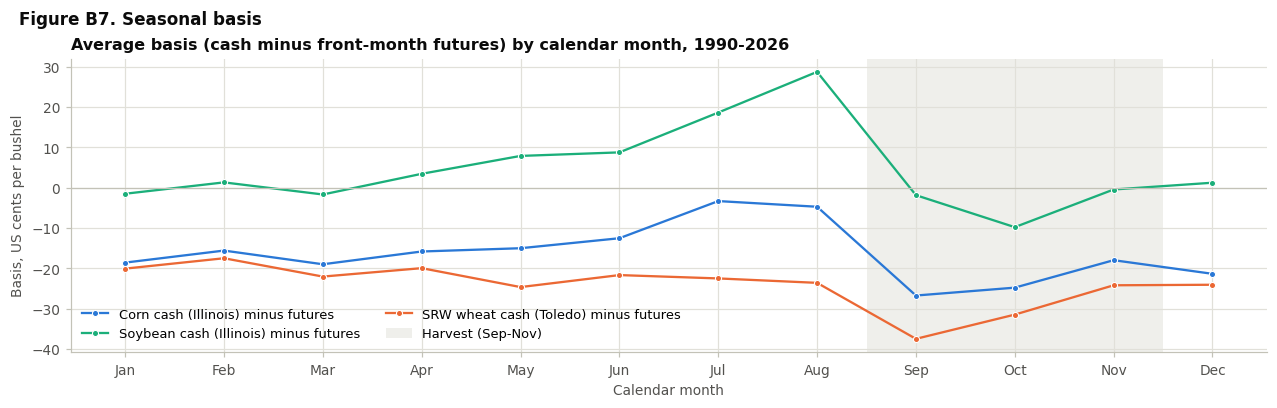

In [23]:
fig, ax = plt.subplots(figsize=(11.5, 3.6), constrained_layout=True)
for c in CASH:
    m = 100 * basis[c].groupby(basis.index.month).mean()
    ax.plot(m.index, m, marker="o", ms=4, mec="white", mew=0.7, color=COLOR_OF[c], label=f"{LABELS[c]} minus futures")
ax.axvspan(8.5, 11.5, color=GRID, alpha=0.5, lw=0, label="Harvest (Sep-Nov)")
ax.axhline(0, color=AXIS, lw=0.8)
ax.set_xticks(range(1, 13), [calendar.month_abbr[m] for m in range(1, 13)])
ax.set_title("Average basis (cash minus front-month futures) by calendar month, 1990-2026", loc="left")
ax.set_xlabel("Calendar month")
ax.set_ylabel("Basis, US cents per bushel")
ax.legend(loc="lower left", ncol=2)
fig_title(fig, "Figure B7. Seasonal basis")
plt.show()

## 9. Key results
Data to 26 October 2026. The report discusses the significance of each result.
- **Rolls:** with both CBOT expiry rules, corn's daily excess kurtosis falls from 20.6 to 2.8.
- **Serial correlation and mean reversion:** daily futures returns are close to white noise and variance ratios are near 1; monthly averaging alone creates autocorrelation of 0.18 to 0.29.
- **GARCH and seasonality:** volatility is persistent (a shock halves in 57 to 88 trading days) and seasonal (corn 16% a year in February, 30% in July).
- **Weather to prices:** a 1% yield shortfall raises the season futures return by 1.34% for corn and 0.67% for soybeans.
- **Corn and wheat, 1990–2026:** cointegrated in each decade since 2000; faster adjustment since 2020 (half-life 5.1 to 1.8 months, $p = 0.032$).
- **US vs EU with cash prices:** half-lives of 3.8 and 3.7 months ($p = 0.89$).
- **Basis:** stationary and seasonal, weakest at harvest; half-life about 35 trading days for corn.

## Works Cited
- Andersen, Torben G., and Tim Bollerslev. "Intraday Periodicity and Volatility Persistence in Financial Markets." *Journal of Empirical Finance*, vol. 4, no. 2–3, 1997, pp. 115–158.
- Anderson, T. W., and Herman Rubin. "Estimation of the Parameters of a Single Equation in a Complete System of Stochastic Equations." *The Annals of Mathematical Statistics*, vol. 20, no. 1, 1949, pp. 46–63.
- Bloomberg L.P. "Daily Prices of CBOT Corn, Wheat and Soybean Futures (C 1, W 1, KW1, S 1 Comdty) and USDA Cash Grain Prices (CORNILNC, SOYBTC1Y, WEAT2RDR Index), 1990–2026." *Bloomberg Terminal*, data supplied by the course instructor, 27 Oct. 2026.
- Bollerslev, Tim. "Generalized Autoregressive Conditional Heteroskedasticity." *Journal of Econometrics*, vol. 31, no. 3, 1986, pp. 307–327.
- Driscoll, John C., and Aart C. Kraay. "Consistent Covariance Matrix Estimation with Spatially Dependent Panel Data." *The Review of Economics and Statistics*, vol. 80, no. 4, 1998, pp. 549–560.
- Engle, Robert F. "Autoregressive Conditional Heteroscedasticity with Estimates of the Variance of United Kingdom Inflation." *Econometrica*, vol. 50, no. 4, 1982, pp. 987–1007.
- Engle, Robert F., and C. W. J. Granger. "Co-Integration and Error Correction: Representation, Estimation, and Testing." *Econometrica*, vol. 55, no. 2, 1987, pp. 251–276.
- European Commission. "Cereals Prices." *Agri-food Data Portal*, agridata.ec.europa.eu. Accessed 28 Sept. 2026.
- Glosten, Lawrence R., et al. "On the Relation between the Expected Value and the Volatility of the Nominal Excess Return on Stocks." *The Journal of Finance*, vol. 48, no. 5, 1993, pp. 1779–1801.
- Johansen, Søren. "Estimation and Hypothesis Testing of Cointegration Vectors in Gaussian Vector Autoregressive Models." *Econometrica*, vol. 59, no. 6, 1991, pp. 1551–1580.
- Kwiatkowski, Denis, et al. "Testing the Null Hypothesis of Stationarity against the Alternative of a Unit Root." *Journal of Econometrics*, vol. 54, no. 1–3, 1992, pp. 159–178.
- Ljung, G. M., and G. E. P. Box. "On a Measure of Lack of Fit in Time Series Models." *Biometrika*, vol. 65, no. 2, 1978, pp. 297–303.
- Lo, Andrew W., and A. Craig MacKinlay. "Stock Market Prices Do Not Follow Random Walks: Evidence from a Simple Specification Test." *The Review of Financial Studies*, vol. 1, no. 1, 1988, pp. 41–66.
- NASA Langley Research Center. "POWER Data Access." *Prediction of Worldwide Energy Resources (POWER)*, power.larc.nasa.gov. Accessed 28 Sept. 2026.
- Newey, Whitney K., and Kenneth D. West. "A Simple, Positive Semi-Definite, Heteroskedasticity and Autocorrelation Consistent Covariance Matrix." *Econometrica*, vol. 55, no. 3, 1987, pp. 703–708.
- Stock, James H., and Mark W. Watson. "A Simple Estimator of Cointegrating Vectors in Higher Order Integrated Systems." *Econometrica*, vol. 61, no. 4, 1993, pp. 783–820.
- United States Department of Agriculture, Foreign Agricultural Service. *Production, Supply and Distribution Online*, apps.fas.usda.gov/psdonline. Accessed 28 Sept. 2026.
- Working, Holbrook. "Note on the Correlation of First Differences of Averages in a Random Chain." *Econometrica*, vol. 28, no. 4, 1960, pp. 916–918.